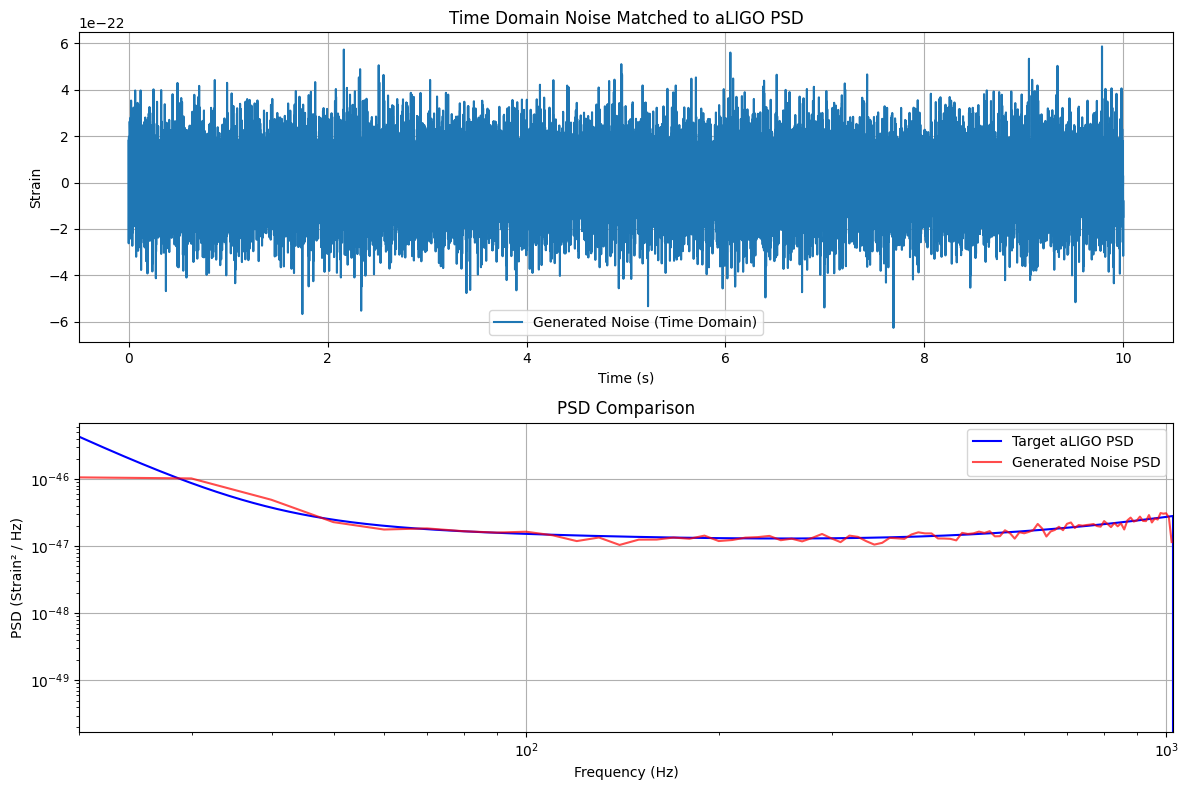

In [43]:
# 导入PyCBC核心库
import pycbc.psd
import pycbc.noise
import pycbc.types
import matplotlib.pyplot as plt

# ====================== 第一步：定义基础参数 ======================
# 采样率（LIGO常用值，单位：Hz）
sample_rate = 2048
# 时间分辨率/采样间隔（delta_t = 1/采样率，单位：秒）
delta_t = 1.0 / sample_rate
# 生成的噪声时长（单位：秒）
duration = 10
# 频率分辨率（单位：Hz）
delta_f = 1.0 / duration
# 最小频率（LIGO敏感频段下限）
f_low = 20.0
# 最大频率（奈奎斯特频率）
f_high = sample_rate / 2
# PSD序列的长度（正整数，必须）
psd_length = int(f_high / delta_f) + 1

# ====================== 第二步：生成目标PSD ======================
# 生成aLIGO零差设计曲线的PSD（参数：长度、频率分辨率、最低截止频率）
psd = pycbc.psd.aLIGOZeroDetHighPower(psd_length, delta_f, f_low)

# 生成频率轴（仅用于绘图）
freqs = pycbc.types.Array(range(psd_length)) * delta_f

# psd_file_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/injections/psd/GW150914_095045/GW150914_095045_H1_noise_psd.txt"
# psd = pycbc.psd.read.from_txt(
#     filename=psd_file_path,
#     length=psd_length,
#     delta_f=delta_f,
#     low_freq_cutoff=f_low,
#     # is_asd=False  # 关键：如果文件是ASD则设为True，PSD设为False
# )

# ====================== 第三步：生成匹配PSD的时域噪声 ======================
# 核心修复：用delta_t替代sample_rate，这是noise_from_psd的标准参数
noise_ts = pycbc.noise.noise_from_psd(
    length=int(sample_rate * duration),  # 总数据点 = 采样率 × 时长
    delta_t=delta_t,                    # 时间分辨率（替代sample_rate）
    psd=psd,
    seed=12345                          # 固定随机种子，结果可复现
)

# ====================== 第四步：可视化验证 ======================
plt.figure(figsize=(12, 8))

# 子图1：时域噪声波形
plt.subplot(2, 1, 1)
noise_ts.plot(label='Generated Noise (Time Domain)')
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title('Time Domain Noise Matched to aLIGO PSD')
plt.legend()
plt.grid(True)

# 子图2：PSD对比（验证生成噪声和目标PSD一致）
plt.subplot(2, 1, 2)
# 计算生成噪声的PSD（指定频率分辨率delta_f）
noise_psd = noise_ts.psd(delta_f)
# 绘制目标PSD和生成噪声的PSD
plt.loglog(freqs, psd, label='Target aLIGO PSD', color='blue')
plt.loglog(noise_psd.sample_frequencies, noise_psd, label='Generated Noise PSD', color='red', alpha=0.7)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (Strain² / Hz)')
plt.title('PSD Comparison')
plt.xlim(f_low, f_high)  # 仅显示10Hz以上的敏感频段
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

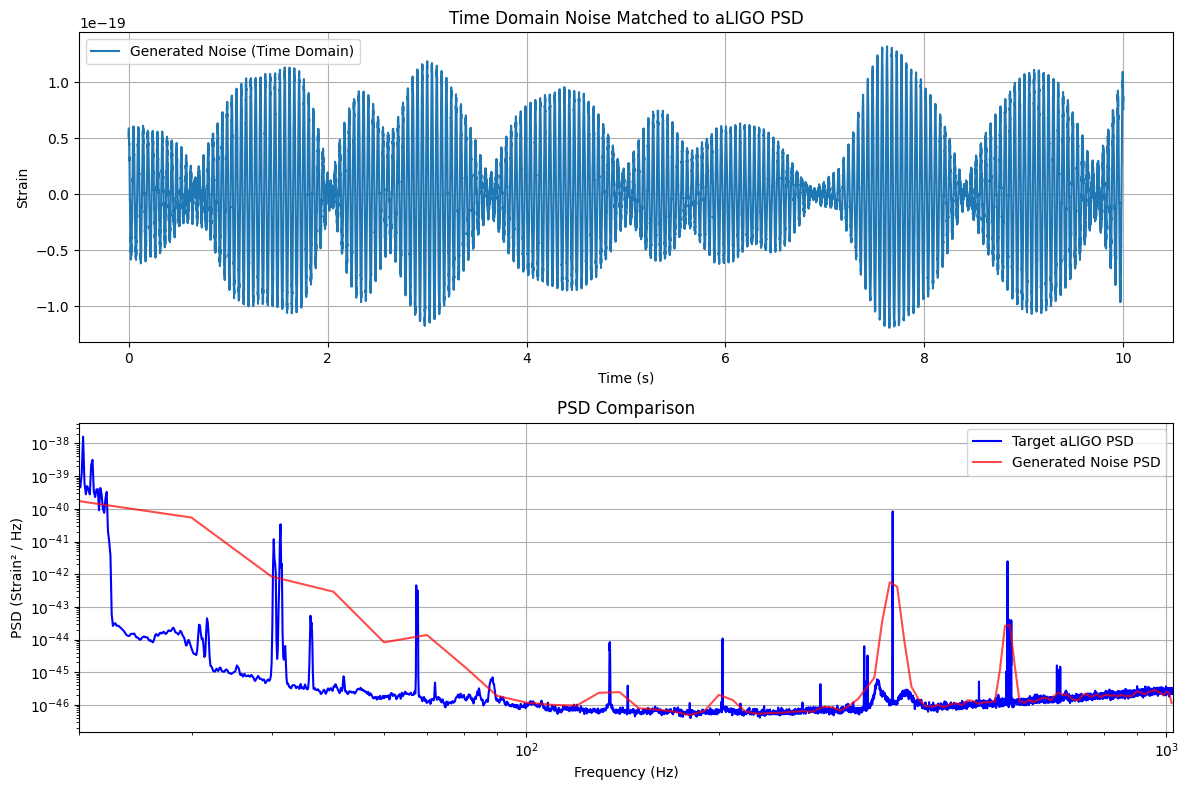

In [46]:
# 导入PyCBC核心库
import pycbc.psd
import pycbc.noise
import pycbc.types
import matplotlib.pyplot as plt

# ====================== 第一步：定义基础参数 ======================
# 采样率（LIGO常用值，单位：Hz）
sample_rate = 2048
# 时间分辨率/采样间隔（delta_t = 1/采样率，单位：秒）
delta_t = 1.0 / sample_rate
# 生成的噪声时长（单位：秒）
duration = 10
# 频率分辨率（单位：Hz）
delta_f = 1.0 / duration
# 最小频率（LIGO敏感频段下限）
f_low = 20.0
# 最大频率（奈奎斯特频率）
f_high = sample_rate / 2
# PSD序列的长度（正整数，必须）
psd_length = int(f_high / delta_f) + 1

# ====================== 第二步：生成目标PSD ======================
# 生成aLIGO零差设计曲线的PSD（参数：长度、频率分辨率、最低截止频率）
psd = pycbc.psd.aLIGOZeroDetHighPower(psd_length, delta_f, f_low)

# 生成频率轴（仅用于绘图）
freqs = pycbc.types.Array(range(psd_length)) * delta_f

psd_file_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/injections/psd/GW150914_095045/GW150914_095045_H1_noise_psd.txt"
psd = np.sqrt(pycbc.psd.read.from_txt(
    filename=psd_file_path,
    length=psd_length,
    delta_f=delta_f,
    low_freq_cutoff=f_low,
    # is_asd=False  # 关键：如果文件是ASD则设为True，PSD设为False
))

# ====================== 第三步：生成匹配PSD的时域噪声 ======================
# 核心修复：用delta_t替代sample_rate，这是noise_from_psd的标准参数
noise_ts = pycbc.noise.noise_from_psd(
    length=int(sample_rate * duration),  # 总数据点 = 采样率 × 时长
    delta_t=delta_t,                    # 时间分辨率（替代sample_rate）
    psd=psd,
    seed=170608                          # 固定随机种子，结果可复现
)

# ====================== 第四步：可视化验证 ======================
plt.figure(figsize=(12, 8))

# 子图1：时域噪声波形
plt.subplot(2, 1, 1)
noise_ts.plot(label='Generated Noise (Time Domain)')
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.title('Time Domain Noise Matched to aLIGO PSD')
plt.legend()
plt.grid(True)

# 子图2：PSD对比（验证生成噪声和目标PSD一致）
plt.subplot(2, 1, 2)
# 计算生成噪声的PSD（指定频率分辨率delta_f）
noise_psd = noise_ts.psd(delta_f)
# 绘制目标PSD和生成噪声的PSD
plt.loglog(freqs, psd, label='Target aLIGO PSD', color='blue')
plt.loglog(noise_psd.sample_frequencies, noise_psd, label='Generated Noise PSD', color='red', alpha=0.7)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (Strain² / Hz)')
plt.title('PSD Comparison')
plt.xlim(f_low, f_high)  # 仅显示10Hz以上的敏感频段
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [39]:
sample_rate * duration

40960

In [33]:
noise_ts.data

array([0., 0., 0., ..., 0., 0., 0.])

In [24]:
len(freqs)

32769

In [21]:
len(freqs)

32769

In [9]:
1/0.0625

16.0